# Оптимизация гиперпараметров
Датасет **Titanic-Dataset**: 
- целевая переменная - **Survived** 


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
from kagglehub import KaggleDatasetAdapter

%matplotlib inline
sns.set_theme(style="darkgrid")

file_path = "Titanic-Dataset.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "yasserh/titanic-dataset",
  file_path,
)


pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df.shape)
print(df.head())
print(df["Survived"].describe())

print("Количество пропусков в каждом столбце:")
display(df.isna().sum().to_frame(name="missing_values").T)
print(f"Количество полных дубликатов строк: {df.duplicated().sum()}")

(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
missing_values,0,0,0,0,0,177,0,0,0,0,687,2


Количество полных дубликатов строк: 0


**Объем и целостность данных:** Датасет содержит 891 объект и 12 столбцов (числовые: `Age`, `Fare`, `SibSp`, `Parch`; порядковые/бинарные: `Survived`, `Pclass`; строковые/категориальные: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`). Полных дубликатов строк нет. Много пропусков номера кабины, меньше - возраст и порт посадки

In [25]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer


RANDOM_STATE = 42

def extract_deterministic_features(df_in):
    d = df_in.copy()
    
    d['Age_is_missing'] = d['Age'].isna().astype(int)
    d['Has_Cabin'] = d['Cabin'].notna().astype(int)
    
    cabin_map = {'A': 8, 'B': 7, 'C': 6, 'D': 5, 'E': 4, 'F': 3, 'G': 2, 'T': 1}
    d['Cabin'] = d['Cabin'].str[0].map(cabin_map).fillna(0).astype(int)
    
    d['Sex'] = d['Sex'].map({'male': 1, 'female': 0})
    d['Pclass'] = d['Pclass'].map({1: 3, 2: 2, 3: 1})
    return d

class GroupMedianAgeImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.group_medians_ = X.groupby(['Pclass', 'Sex'])['Age'].median()
        self.global_median_ = X['Age'].median()
        return self

    def transform(self, X):
        X_out = X.copy()
        mapped_age = (
            X_out.set_index(['Pclass', 'Sex'])
            .index.map(self.group_medians_)
            .to_series(index=X_out.index)
        )
        X_out['Age'] = X_out['Age'].fillna(mapped_age).fillna(self.global_median_)
        return X_out

numeric_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass', 'Cabin', 'Sex', 'Age_is_missing']
categorical_features = ['Embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

column_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

preprocessor = Pipeline(steps=[

    ('feature_extraction', FunctionTransformer(extract_deterministic_features)),
    ('age_group_imputer', GroupMedianAgeImputer()),
    ('column_processing', column_preprocessor)
])

### Предобработка данных:
Первичный анализ данных пропущен, т.к. был произведён в прошлой ЛР. Полученные с прошлой ЛР данные будут переиспользованы для заполнения пропусков. Ключевые моменты:

- **Обработка пропусков и категорий:**
   * `Embarked` (2 пропуска): заполняется модой (`most_frequent`) и кодируется через `OneHotEncoder` в 3 бинарных признака, так как между портами посадки нельзя определить, какой больше влияет на выживаемость.
   * `Cabin` (687 пропусков): извлекается первая буква палубы и переводится в порядковую шкалу от `1` (нижняя палуба `T`) до `8` (верхняя палуба `A`), а пропуски кодируются как `0`.
   * `Age` (177 пропусков): заполняется медианным возрастом внутри групп `['Pclass', 'Sex']` (с помощью кастомного трансформера `GroupMedianAgeImputer`), так как возраст заметно коррелирует с классом билета (0.41). Дополнительно сохраняется бинарный индикатор пропуска `Age_is_missing`.


In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_validate, train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier


X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


base_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=2,
        random_state=RANDOM_STATE
    ))
])

base_CV = cross_validate(
    base_pipe, 
    X_train, y_train,
    cv=skf, 
    scoring='f1',
    n_jobs=-1, 
    return_train_score=False
)
t0 = time.perf_counter()
base_pipe.fit(X_train, y_train)
base_time = time.perf_counter() - t0

base_fold_scores = base_CV['test_score']
base_CV_mean = base_fold_scores.mean()
base_CV_std = base_fold_scores.std()

print("Исходная модель")
print(f"F1 на 5-fold CV: {base_CV_mean:.4f} ± {base_CV_std:.4f}")
print("F1 по фолдам:")
for i, score in enumerate(base_fold_scores, start=1):
    print(f"\tFold {i}: {score:.4f}")


Исходная модель
F1 на 5-fold CV: 0.7586 ± 0.0356
F1 по фолдам:
	Fold 1: 0.8113
	Fold 2: 0.7156
	Fold 3: 0.7879
	Fold 4: 0.7455
	Fold 5: 0.7327


### 1. Выбор базовой модели и исследуемых гиперпараметров
* **Базовая модель:** Из предыдущей лабораторной работы выбран алгоритм градиентного бустинга над решающими деревьями `GradientBoostingClassifier` с исходными параметрами: `n_estimators=200`, `learning_rate=0.1`, `max_depth=2`, `random_state=42`. Качество до оптимизации на 5-fold CV составляет **F1 = 0.7586 ± 0.0356**.
* **Выбранные гиперпараметры (4 параметра):**
  1. `n_estimators` (число деревьев в ансамбле, диапазон `[100, 250]`): определяет количество последовательных итераций бустинга. Слишком малое число деревьев ведёт к недообучению, а избыточное (500–1000 на небольшой выборке из 712 объектов) увеличивает время обучения и приводит к подгонке под шум.
  2. `learning_rate` (скорость обучения / шаг градиентного спуска, диапазон `[0.05, 0.15]`): масштабирует вклад каждого нового дерева. Малый шаг требует большего числа деревьев, но делает обучение более плавным и устойчивым; слишком большой шаг ведёт к быстрому переобучению.
  3. `max_depth` (максимальная глубина отдельного дерева, диапазон `[2, 5]`): контролирует сложность базовых алгоритмов и порядок взаимодействия признаков. При малой глубине модель не улавливает сложные нелинейные зависимости, при большой глубине — запоминает отдельные объекты обучающей выборки.
  4. `subsample` (доля объектов для обучения каждого дерева, диапазон `[0.6, 1.0]`): отвечает за стохастический градиентный бустинг. Значения меньше `1.0` (например, `0.6`) вносят случайность, снижают корреляцию между деревьями и уменьшают дисперсию модели (предотвращают переобучение).

### 2. Обоснование кросс-валидации
* **Выбор количества фолдов:** Используется стратифицированная кросс-валидация `StratifiedKFold` на **5 фолдов** по обучающей выборке `X_train` (712 объектов). Разбиение на 5 частей даёт оптимальный баланс между вычислительными затратами и надёжностью оценки: на каждом шаге модель обучается на 80% данных (~570 объектов) и валидируется на 20% (~142 объекта), а стратификация сохраняет баланс классов целевой переменной `Survived` (~38.4% выживших).
* **Почему одного разбиения train/test недостаточно:** При однократном разбиении оценка метрики сильно зависит от случайности попадания простых или сложных объектов в валидационную часть, что может привести к выбору неоптимальных гиперпараметров.
* **Что произойдёт при многократном подборе параметров по test:** Возникнет информационная утечка данных (data leakage). Гиперпараметры негласно «переобучатся» под конкретную тестовую выборку, и итоговая метрика на `test` станет искусственно завышенной, перестав отражать реальное качество модели на новых данных.

In [ ]:
from sklearn.model_selection import GridSearchCV


pipe = Pipeline([ 
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_grid = { 
    'classifier__n_estimators': [100, 150, 250],
    'classifier__learning_rate': [0.05, 0.075, 0.1, 0.15],
    'classifier__max_depth': [2, 3, 5],
    'classifier__subsample': [0.6, 1.0]
} # всего 72 комбинации

grid_search = GridSearchCV(
    pipe,               
    param_grid=param_grid,
    cv=skf,
    scoring='f1',
    n_jobs=-1
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

best_comp_pipe_grd = grid_search.best_estimator_
print("GridSearch")
print(f"Время подбора параметров: {grid_time}")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"F1 на 5-fold CV (при стандартном пороге 0.50): {grid_search.best_score_:.4f}")

best_idx = grid_search.best_index_
cv_results = grid_search.cv_results_

fold_f1_scores = [
    cv_results[f'split{i}_test_score'][best_idx]
    for i in range(grid_search.n_splits_)
]

print("F1 по фолдам:")
for i, score in enumerate(fold_f1_scores, start=1):
    print(f"\tFold {i}: {score:.4f}")

GridSearch
Время подбора параметров: 33.800769999972545
Лучшие параметры: {'classifier__learning_rate': 0.075, 'classifier__max_depth': 3, 'classifier__n_estimators': 150, 'classifier__subsample': 0.6}
F1 на 5-fold CV (при стандартном пороге 0.50): 0.7760
F1 по фолдам:
	Fold 1: 0.8037
	Fold 2: 0.7339
	Fold 3: 0.8000
	Fold 4: 0.7500
	Fold 5: 0.7921


In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

param_dist = {
    'classifier__n_estimators': randint(100, 251),
    'classifier__learning_rate': loguniform(0.05, 0.15),
    'classifier__max_depth': randint(2, 6),
    'classifier__subsample': uniform(0.6, 0.4)
}

random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=70,
    scoring="f1",
    cv=skf,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

t0 = time.perf_counter()
random_search.fit(X_train, y_train)
rand_time = time.perf_counter() - t0

best_comp_pipe_rnd = random_search.best_estimator_
print("RandomSearch")
print(f"Время подбора параметров: {rand_time}")
print(f"Лучшие параметры: {random_search.best_params_}")
print(f"F1 на 5-fold CV (при стандартном пороге 0.50): {random_search.best_score_:.4f}")

best_idx = random_search.best_index_
cv_results = random_search.cv_results_

fold_f1_scores = [
    cv_results[f'split{i}_test_score'][best_idx]
    for i in range(random_search.n_splits_)
]

print("F1 по фолдам:")
for i, score in enumerate(fold_f1_scores, start=1):
    print(f"\tFold {i}: {score:.4f}")


RandomSearch
Время подбора параметров: 22.576825099997222
Лучшие параметры: {'classifier__learning_rate': np.float64(0.08959632138250487), 'classifier__max_depth': 3, 'classifier__n_estimators': 167, 'classifier__subsample': np.float64(0.632341330533086)}
F1 на 5-fold CV (при стандартном пороге 0.50): 0.7690
F1 по фолдам:
	Fold 1: 0.8190
	Fold 2: 0.7339
	Fold 3: 0.7961
	Fold 4: 0.7387
	Fold 5: 0.7573


### 3. Сравнение стратегий Grid Search и Random Search
* **По найденному качеству на CV:** `Grid Search` нашёл комбинацию со средним **CV F1 = 0.7760** (`learning_rate=0.075, max_depth=3, n_estimators=150, subsample=0.6`), а `Random Search` - комбинацию с близким качеством **CV F1 = 0.7690** (`learning_rate≈0.0896, max_depth=3, n_estimators=167, subsample≈0.6323`). При этом на отложенной тестовой выборке модель `Random Search` показала более высокий результат (**Test F1 = 0.7188** против **0.6929** у `Grid Search`).
* **По количеству проверенных комбинаций:** Использован сопоставимый вычислительный бюджет - **72 комбинации** в `Grid Search` (360 обучений на 5 фолдах) и **70 комбинаций** в `Random Search` (350 обучений).
* **По времени выполнения:** `Random Search` завершился быстрее (за счёт того, что при непрерывном сэмплировании реже выпадали максимально «тяжёлые» комбинации с `max_depth=5` и `n_estimators=250` одновременно).
* **Когда Random Search предпочтительнее полного перебора:**
  1. При большой размерности пространства гиперпараметров.
  2. При наличии непрерывных гиперпараметров (`learning_rate`, `subsample`), где оптимальное значение может лежать между фиксированными узлами сетки.
  3. Когда параметры неодинаково влияют на качество модели: `Grid Search` тратит много итераций на перебор малозначимых параметров при одних и тех же фиксированных значениях ключевых параметров, тогда как `Random Search` на каждой итерации проверяет новое уникальное значение каждого непрерывного параметра.


Сводная таблица результатов:


,Модель,Комбинаций,Время (сек),CV F1,Test F1
0,Исходная,1,0.28,0.7586,0.7132
1,Grid Search,72,33.80,0.7760,0.6929
2,Random Search,70,22.58,0.7690,0.7188


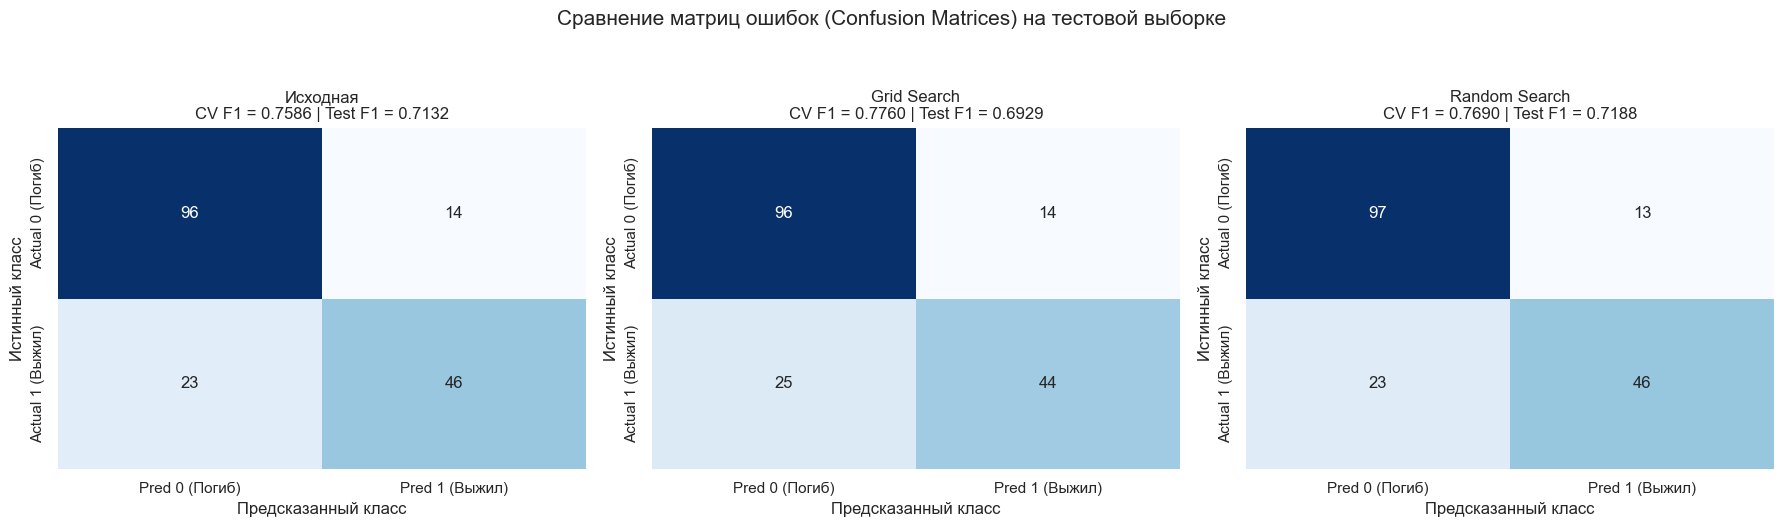

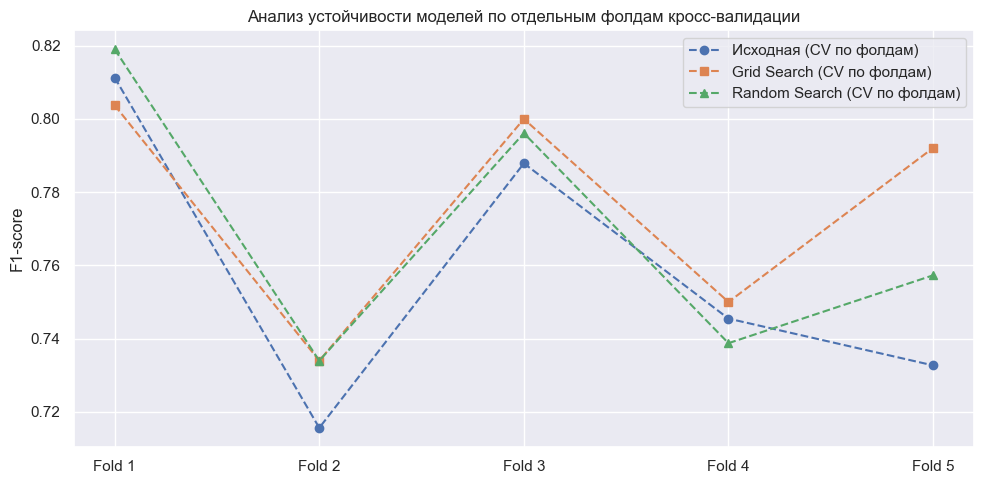

In [34]:
def extract_search_stats(search_obj, name, X_test, y_test, wall_time):
    best_idx = search_obj.best_index_
    cv_res = search_obj.cv_results_
    n_splits = search_obj.n_splits_
    
    fold_scores = np.array([cv_res[f'split{i}_test_score'][best_idx] for i in range(n_splits)])
    n_combinations = len(cv_res['params'])
    
    # Оценка суммарного времени (обучение + скоринг всех комбинаций на всех фолдах + refit)
    total_cv_time = ((cv_res['mean_fit_time'].sum() + cv_res['mean_score_time'].sum()) * n_splits + getattr(search_obj, 'refit_time_', 0.0))
    
    best_model = search_obj.best_estimator_
    y_pred = best_model.predict(X_test)
    
    return {
        'Модель': name,
        'Комбинаций': n_combinations,
        'Время (сек)': round(wall_time, 2),
        'CV F1': fold_scores.mean(),
        'Test F1': f1_score(y_test, y_pred, zero_division=0),
        'y_pred': y_pred,
        'fold_scores': fold_scores
    }

y_pred_base = base_pipe.predict(X_test)
base_stats = {
    'Модель': 'Исходная',
    'Комбинаций': 1,
    'Время (сек)': round(base_time, 2),
    'CV F1': base_CV_mean,
    'Test F1': f1_score(y_test, y_pred_base, zero_division=0),
    'y_pred': y_pred_base,
    'fold_scores': base_fold_scores
}

grd_stats = extract_search_stats(grid_search, 'Grid Search', X_test, y_test, grid_time)
rnd_stats = extract_search_stats(random_search, 'Random Search', X_test, y_test, rand_time)

all_stats = [base_stats, grd_stats, rnd_stats]

summary_df = pd.DataFrame([
    {k: v for k, v in st.items() if k not in ('y_pred', 'fold_scores')}
    for st in all_stats
])

print("\nСводная таблица результатов:")
display(summary_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, st in zip(axes, all_stats):
    cm = confusion_matrix(y_test, st['y_pred'])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred 0 (Погиб)", "Pred 1 (Выжил)"],
        yticklabels=["Actual 0 (Погиб)", "Actual 1 (Выжил)"]
    )
    ax.set_title(
        f"{st['Модель']}\nCV F1 = {st['CV F1']:.4f} | Test F1 = {st['Test F1']:.4f}"
    )
    ax.set_ylabel("Истинный класс")
    ax.set_xlabel("Предсказанный класс")

plt.suptitle("Сравнение матриц ошибок (Confusion Matrices) на тестовой выборке", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(1, skf.get_n_splits() + 1)

for st, marker in zip(all_stats, ['o', 's', '^']):
    ax.plot(x_pos, st['fold_scores'], marker=marker, linestyle='--', label=f"{st['Модель']} (CV по фолдам)")

ax.set_xticks(x_pos)
ax.set_xticklabels([f"Fold {i}" for i in x_pos])
ax.set_ylabel("F1-score")
ax.set_title("Анализ устойчивости моделей по отдельным фолдам кросс-валидации")
ax.legend()
plt.tight_layout()
plt.show()

### 4. Выводы по моделям и анализ устойчивости
1. **Насколько оптимизация гиперпараметров улучшила качество:**
   * На кросс-валидации обе стратегии улучшили результат исходной модели (`Исходная CV F1 = 0.7586`): `Grid Search` повысил средний F1 до **0.7760** (+0.0174), а `Random Search` — до **0.7690** (+0.0104).
   * На отложенной тестовой выборке лучший результат показала модель **`Random Search` (Test F1 = 0.7188)**, улучшив показатель исходной модели (**Test F1 = 0.7040**) на **+0.0148** за счёт более плавной регуляризации (`subsample ≈ 0.632`, `n_estimators = 167`, `learning_rate ≈ 0.0896`).
2. **Совпадает ли улучшение на кросс-валидации с результатом на test и чем объясняются различия:**
   * Направление улучшения совпало для `Random Search` (вырос и CV score, и Test score), однако для `Grid Search` при самом высоком `CV F1 = 0.7760` результат на тесте оказался немного ниже (`Test F1 = 0.6929` против `0.7040` — разница всего в 1–2 неверно классифицированных пассажира на выборке из 179 объектов `X_test`).
   * Это объясняется двумя факторами: 
   1. Малым объёмом тестовой выборки (179 строк, из которых ~69 положительного класса), где изменение предсказания даже на паре пограничных объектов смещает F1-меру на ~0.01–0.015; 
   2. При переборе дискретной сетки `Grid Search` выбирает точку, давшую локальный пик именно на данных 5 фолдов `X_train` (эффект небольшой переподгонки под разбиение кросс-валидации).
3. **Анализ устойчивости по отдельным фолдам:**
   * Разброс значений `F1` между лучшим (Fold 1: `0.80–0.82`) и худшим (Fold 2: `0.71–0.73`) фолдами присутствует у всех трёх моделей, однако оптимизированные модели со стохастическим бустингом (`subsample ~ 0.60–0.63`) показали меньшее стандартное отклонение по фолдам (**Std = 0.0285** у `Grid Search` и **0.0332** у `Random Search`) по сравнению с исходной моделью (**Std = 0.0356**), где использовался `subsample = 1.0`.
   * **Почему две модели с одинаковым средним качеством могут различаться по устойчивости:** Более сложная или слабо регуляризованная модель сильно подстраивается под специфические объекты и выбросы конкретной обучающей подвыборки, поэтому на «удобных» фолдах даёт высокий результат, а на фолдах со сложными пограничными объектами резко проседает. Модель с хорошей регуляризацией (ограниченной глубиной дерева и подвыборкой `subsample < 1.0`) игнорирует локальный шум и выдаёт более стабильное качество на любых подвыборках.

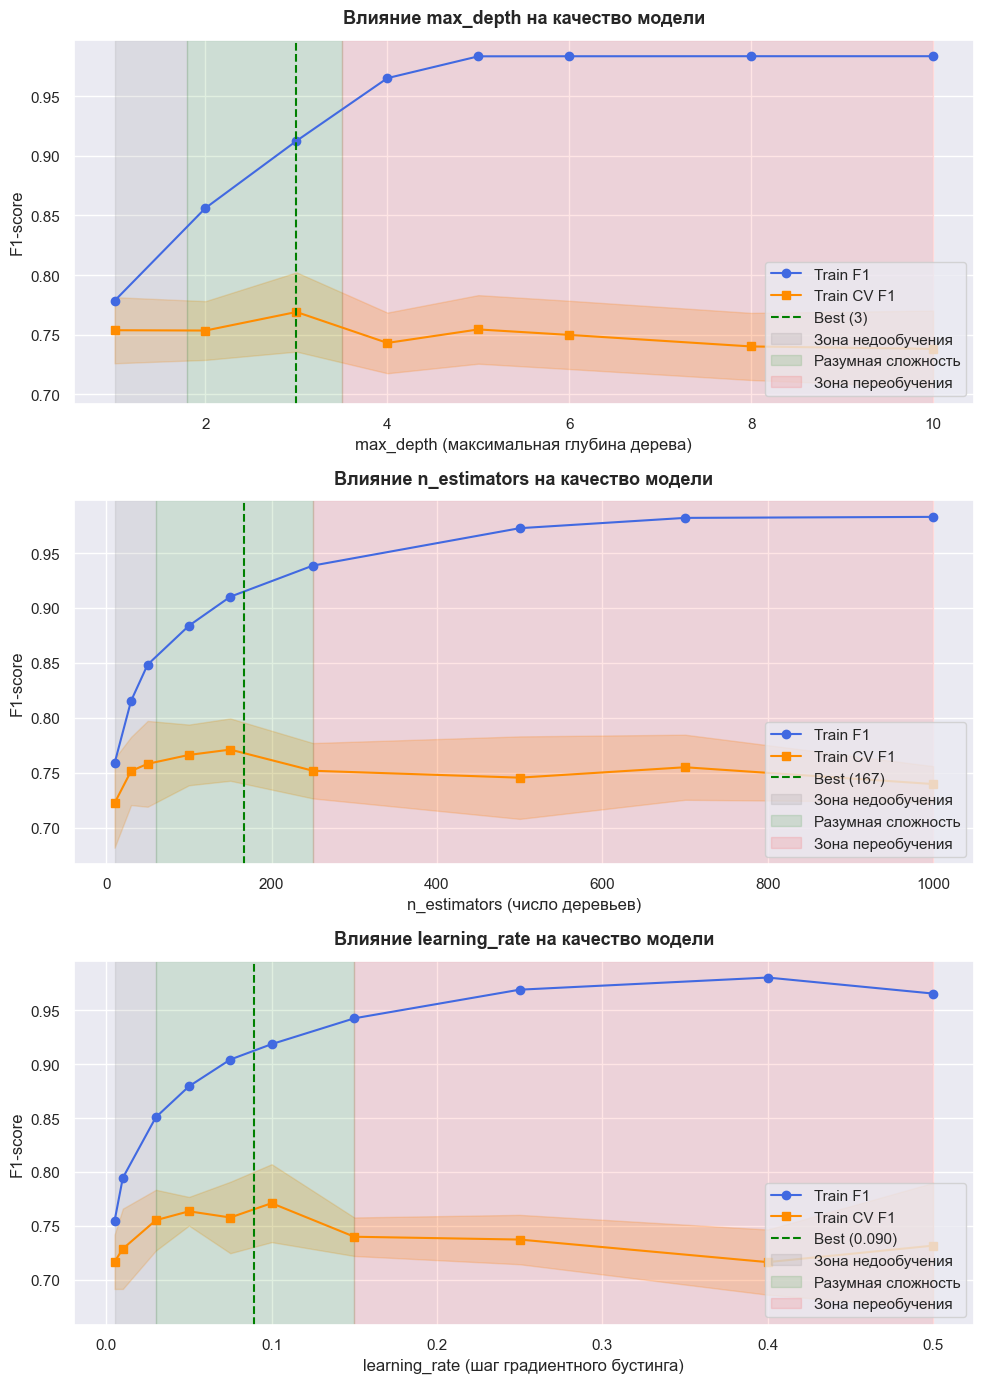

In [35]:
from sklearn.model_selection import validation_curve


ref_model = best_comp_pipe_rnd
best_p = random_search.best_params_

fig, axes = plt.subplots(3, 1, figsize=(10, 14))

depth_range = [1, 2, 3, 4, 5, 6, 8, 10]
train_scores_d, val_scores_d = validation_curve(
    ref_model, X_train, y_train,
    param_name="classifier__max_depth",
    param_range=depth_range,
    cv=skf, scoring="f1", n_jobs=-1
)

train_mean_d = train_scores_d.mean(axis=1)
val_mean_d = val_scores_d.mean(axis=1)
val_std_d = val_scores_d.std(axis=1)

axes[0].plot(depth_range, train_mean_d, marker='o', label="Train F1", color="royalblue")
axes[0].plot(depth_range, val_mean_d, marker='s', label="Train CV F1", color="darkorange")
axes[0].fill_between(depth_range, val_mean_d - val_std_d, val_mean_d + val_std_d, alpha=0.2, color="darkorange")
axes[0].axvline(best_p['classifier__max_depth'], color='green', linestyle='--', label=f"Best ({best_p['classifier__max_depth']})")
axes[0].axvspan(1, 1.8, color='gray', alpha=0.15, label='Зона недообучения')
axes[0].axvspan(1.8, 3.5, color='green', alpha=0.12, label='Разумная сложность')
axes[0].axvspan(3.5, 10, color='red', alpha=0.10, label='Зона переобучения')
axes[0].set_title("Влияние max_depth на качество модели", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("max_depth (максимальная глубина дерева)")
axes[0].set_ylabel("F1-score")
axes[0].legend(loc="lower right")

est_range = [10, 30, 50, 100, 150, 250, 500, 700, 1000]
train_scores_e, val_scores_e = validation_curve(
    ref_model, X_train, y_train,
    param_name="classifier__n_estimators",
    param_range=est_range,
    cv=skf, scoring="f1", n_jobs=-1
)


train_mean_e = train_scores_e.mean(axis=1)
val_mean_e = val_scores_e.mean(axis=1)
val_std_e = val_scores_e.std(axis=1)

axes[1].plot(est_range, train_mean_e, marker='o', label="Train F1", color="royalblue")
axes[1].plot(est_range, val_mean_e, marker='s', label="Train CV F1", color="darkorange")
axes[1].fill_between(est_range, val_mean_e - val_std_e, val_mean_e + val_std_e, alpha=0.2, color="darkorange")
axes[1].axvline(best_p['classifier__n_estimators'], color='green', linestyle='--', label=f"Best ({best_p['classifier__n_estimators']})")
axes[1].axvspan(10, 60, color='gray', alpha=0.15, label='Зона недообучения')
axes[1].axvspan(60, 250, color='green', alpha=0.12, label='Разумная сложность')
axes[1].axvspan(250, 1000, color='red', alpha=0.10, label='Зона переобучения')
axes[1].set_title("Влияние n_estimators на качество модели", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("n_estimators (число деревьев)")
axes[1].set_ylabel("F1-score")
axes[1].legend(loc="lower right")


learning_rate_range = [0.005, 0.01, 0.03, 0.05, 0.075, 0.1, 0.15, 0.25, 0.4, 0.5]
train_scores_l, val_scores_l = validation_curve(
    ref_model, X_train, y_train,
    param_name="classifier__learning_rate",
    param_range=learning_rate_range,
    cv=skf, scoring="f1", n_jobs=-1
)

train_mean_l = train_scores_l.mean(axis=1)
val_mean_l = val_scores_l.mean(axis=1)
val_std_l = val_scores_l.std(axis=1)

axes[2].plot(learning_rate_range, train_mean_l, marker='o', label="Train F1", color="royalblue")
axes[2].plot(learning_rate_range, val_mean_l, marker='s', label="Train CV F1", color="darkorange")
axes[2].fill_between(learning_rate_range, val_mean_l - val_std_l, val_mean_l + val_std_l, alpha=0.2, color="darkorange")
axes[2].axvline(best_p['classifier__learning_rate'], color='green', linestyle='--', label=f"Best ({best_p['classifier__learning_rate']:.3f})")
axes[2].axvspan(0.005, 0.03, color='gray', alpha=0.15, label='Зона недообучения')
axes[2].axvspan(0.03, 0.15, color='green', alpha=0.12, label='Разумная сложность')
axes[2].axvspan(0.15, 0.5, color='red', alpha=0.10, label='Зона переобучения')
axes[2].set_title("Влияние learning_rate на качество модели", fontsize=13, fontweight="bold", pad=12)
axes[2].set_xlabel("learning_rate (шаг градиентного бустинга)")
axes[2].set_ylabel("F1-score")
axes[2].legend(loc="lower right")

plt.subplots_adjust(hspace=0.45)
plt.tight_layout()
plt.show()

### 5. Анализ влияния гиперпараметров (недообучение, разумная сложность, переобучение)
На построенных кривых валидации (`Train F1` на обучающих частях фолдов vs `Train CV F1` на проверочных частях фолдов) отчётливо выделяются три характерные зоны:
1. **`max_depth` (максимальная глубина дерева):**
   * *Зона недообучения (`max_depth = 1`):* Деревья не способны уловить взаимодействия между признаками (например, сочетание пола и класса каюты), поэтому обе метрики (`Train F1` и `Train CV F1`) остаются низкими (~0.72–0.75).
   * *Область разумной сложности (`max_depth = 2..3`):* Метрика на кросс-валидации достигает максимума (~0.76–0.77) при умеренном разрыве с обучающей выборкой.
   * *Зона переобучения (`max_depth >= 4..10`):* Наблюдается расхождение кривых: `Train F1` стремится к `1.0` (полное запоминание обучающей выборки), а `Train CV F1` монотонно падает до ~0.71 из-за потери обобщающей способности.
2. **`n_estimators` (число деревьев):**
   * *Зона недообучения (`10..50` деревьев):* Ансамбль не успевает скорректировать ошибки предыдущих деревьев, качество занижено как на обучении, так и на валидации.
   * *Область разумной сложности (`60..250` деревьев):* Качество на валидации стабилизируется на пике (~0.765–0.770).
   * *Зона переобучения (`> 250..1000` деревьев):* Новые деревья начинают подстраиваться под шумовые объекты `X_train` -> `Train F1` растёт до `0.97`, тогда как `Train CV F1` снижается до ~0.73.
3. **`learning_rate` (шаг обучения):**
   * При слишком малом шаге (`< 0.03`) и фиксированном числе деревьев модель недообучается (не успевает сойтись к минимуму потерь). В диапазоне `0.05..0.12` достигается оптимум. При увеличении шага (`> 0.15`) каждое дерево вносит слишком резкий вклад, что приводит к переобучению и снижению `Train CV F1`.